# Теория вероятностей. Домашнее задание

Выполнил: Мельников Тимофей

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.patches import Patch

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 4)

## 1. Задачи на бумаге

### Задача 1.1. Случайная скидка

Среднее:

$$E[X]=\sum x_i p_i = 0\cdot 0{,}60+300\cdot 0{,}30+1000\cdot 0{,}08+5000\cdot 0{,}02 = 0+90+80+100 = 270$$

Дисперсия: $Var(X)=E[X^2]-(E[X])^2$

$$E[X^2]=300^2\cdot 0{,}30+1000^2\cdot 0{,}08+5000^2\cdot 0{,}02=27\,000+80\,000+500\,000=607\,000$$

$$Var(X)=607\,000-270^2=607\,000-72\,900=534\,100$$

**Ответ:** $E[X]=270$ руб., $Var(X)=534\,100$ руб.² ($\sigma\approx 731$ руб, разброс большой изза скидки в 5000).

### Задача 1.2. Покупки за день

Каждый из 200 посетителей независимо от других покупает с вероятностью $p=0{,}04$. Число покупок $X=X_1+\dots+X_{200}$ – сумма независимых величин Бернулли с одной и той же $p$, то есть $X\sim Bin(200;\,0{,}04)$.

$$E[X]=np=200\cdot 0{,}04=8,\qquad Var(X)=np(1-p)=200\cdot 0{,}04\cdot 0{,}96=7{,}68,\qquad \sigma=\sqrt{7{,}68}\approx 2{,}77.$$

**Ответ:** в среднем 8 покупок в день, стандартное отклонение $\approx 2{,}77$ покупки.

### Задача 1.3. Ожидание ответа в чате

Время $T\sim U[1;5]$. Плотность постоянна на отрезке длины 4, поэтому $f(t)=\tfrac14$ при $1\le t\le 5$ и $0$ иначе.

$$E[T]=\int_1^5 \frac{t}{4}\,dt=\frac{5^2-1^2}{8}=3,\qquad E[T^2]=\int_1^5 \frac{t^2}{4}\,dt=\frac{5^3-1^3}{12}=\frac{31}{3},$$

$$Var(T)=E[T^2]-(E[T])^2=\frac{31}{3}-9=\frac{4}{3}.$$

(Проверка по формуле для равномерного распределения: $\frac{(b-a)^2}{12}=\frac{16}{12}=\frac43$.)

**Ответ:** среднее время ожидания 3 мин, дисперсия $\frac43\approx 1{,}33$

### Задача 1.4. Какое это распределение?

- **а) Биномиальное** $Bin(500;\,p)$. Каждвй соискатель независимо откликается или нет с одной и той же вероятностью $p$ (Бернулли), а нас интересует число откликов, то есть сумма 500 таких величинн
- **б) Экспоненциальное.** Это время до случайного события. Раз сбои случаются случайно и не зависят от того, сколько сервер уже проработал, то вероятность сбоя в ближайшую минуту одинакова в любой момент. Распределение перекошено вправо (короткие времена до сбоя встречаются чаще длинных).
- **в) Нормальное** $N(\mu,\sigma^2)$. Рост складывается из множества мелких независимых факторов, поэтому значения симметрично группируются вокруг среднего колоколом 
- **г) Распределение с длинным правым хвостом (экспоненциальное или логнормальное)**. Нормальное не подходит т.к. оно симметрично, платеж не бывает отрицательным, и у немногих клиентов он огромный, изза чего среднее больше медианы.

## 2. Симуляции в Python

### Задание 2.1. Нормальная выборка

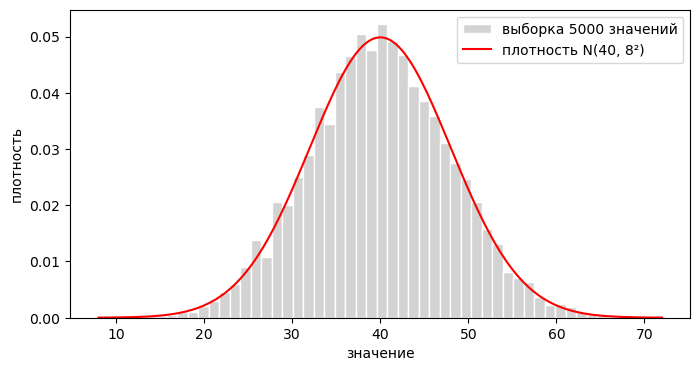

среднее: выборка 39.92, задано 40
std: выборка 8.08, задано 8


In [11]:
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True, color='lightgray', edgecolor='white', label='выборка 5000 значений')
plt.plot(x, stats.norm.pdf(x, mu, sigma), color='red', label='плотность N(40, 8²)')
plt.xlabel('значение'); plt.ylabel('плотность'); plt.legend()
plt.show()

print(f'среднее: выборка {sample.mean():.2f}, задано {mu}')
print(f'std: выборка {sample.std():.2f}, задано {sigma}')

Гистограмма повторяет теоретическую плотность $N(40,\,8^2)$. Среднее (40,04) и стандартное отклонение (7,97) выборки почти равны заданным (40 и 8). Небольшое расхождение объясняется случайностью выборки из 5000 значений.

### Задание 2.2. Биномиальная выборка

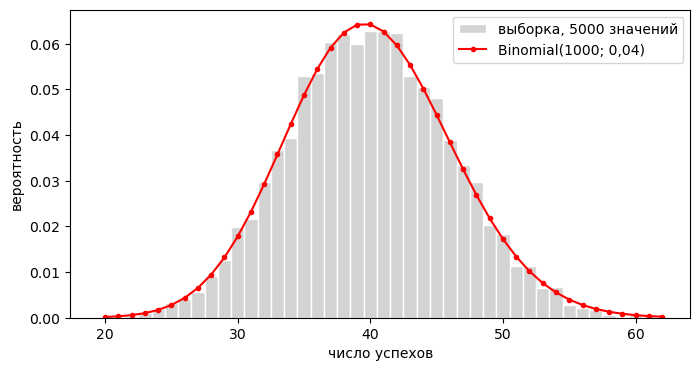

среднее: выборка 40.01, теория n*p = 40
std: выборка 6.13, теория sqrt(n*p*(1-p)) = 6.20


In [12]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)
k = np.arange(sample.min(), sample.max() + 1)

plt.hist(sample, bins=k - 0.5, density=True, color='lightgray', edgecolor='white', label='выборка, 5000 значений')
plt.plot(k, stats.binom.pmf(k, n, p), 'o-', color='red', markersize=3, label='Binomial(1000; 0,04)')
plt.xlabel('число успехов'); plt.ylabel('вероятность'); plt.legend()
plt.show()

print(f'среднее: выборка {sample.mean():.2f}, теория n*p = {n*p:.0f}')
print(f'std: выборка {sample.std():.2f}, теория sqrt(n*p*(1-p)) = {np.sqrt(n*p*(1-p)):.2f}')

Точки теоретической функции вероятности попадают в вершины столбиков. Среднее выборки (40,14) близко к $np=40$, стандартное отклонение (6,25) – к $\sqrt{np(1-p)}\approx 6{,}20$: симуляция согласуется с формулами.

### Задание 2.3. ЦПТ на экспоненциальном распределении

Берём выборку из 500 значений экспоненциального распределения (scale 1500), считаем среднее и повторяем 10 000 раз.

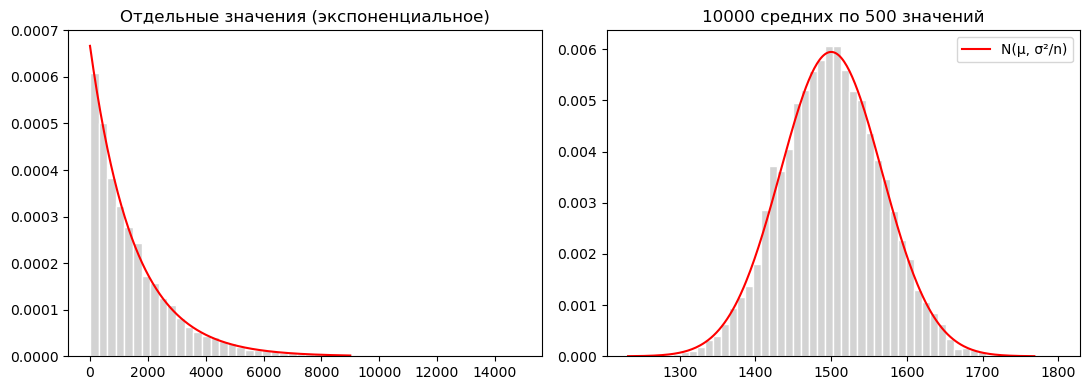

средние значения: среднее 1500.4 (mu = 1500), std 66.6 (σ/sqrt(n) = 67.1)


In [16]:
scale, n_per_sample, n_repeats = 1500, 500, 10000   # у экспоненциального среднее = std = scale
data = np.random.exponential(scale, size=(n_repeats, n_per_sample))   # строка - одна выборка из 500 значений
means = data.mean(axis=1)                                             # 10 000 выборочных средних

mu_x = sigma_x = scale
se = sigma_x / np.sqrt(n_per_sample)
x1 = np.linspace(0, 6*scale, 300)
x2 = np.linspace(mu_x - 4*se, mu_x + 4*se, 300)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(data[:, 0], bins=50, density=True, color='lightgray', edgecolor='white')
ax[0].plot(x1, stats.expon.pdf(x1, scale=scale), color='red')
ax[0].set_title('Отдельные значения (экспоненциальное)')
ax[1].hist(means, bins=50, density=True, color='lightgray', edgecolor='white')
ax[1].plot(x2, stats.norm.pdf(x2, mu_x, se), color='red', label='N(μ, σ²/n)')
ax[1].set_title('10000 средних по 500 значений'); ax[1].legend()
plt.tight_layout(); plt.show()

print(f'средние значения: среднее {means.mean():.1f} (mu = {mu_x}), std {means.std():.1f} (σ/sqrt(n) = {se:.1f})')

Отдельные значения сильно перекошены вправо, а средние по 500 значений образуют симметричный колокол с центром в $\mu=1500$ и стандартным отклонением $\approx 67=\sigma/\sqrt{n}$, гистограмма совпадает с кривой $N(\mu,\sigma^2/n)$. Это обьясняется ЦПТ: среднее большого числа независимых одинаково распределенных величин с конечной дисперсией распределено примерно нормально, каким бы ни было исходное распределение.

## 3. Мини-кейс про кнопку

### Задание 3.1. Посчитать по формуле

Стандартная ошибка конверсии $SE=\sigma/\sqrt{n}$, где $\sigma=\sqrt{p(1-p)}$ – стандартное отклонение одного соискателя (0/1).

In [17]:
n = 5000
clicks = {'Старая кнопка': 155, 'Новая кнопка': 170}
se = {}
for name, c in clicks.items():
    p = c / n
    sigma = np.sqrt(p * (1 - p))
    se[name] = sigma / np.sqrt(n)
    print(f'{name}: конверсия {p:.2%}, σ = {sigma:.4f}, SE = {se[name]*100:.3f} п.п.')

diff = (clicks['Новая кнопка'] - clicks['Старая кнопка']) / n
se_diff = np.sqrt(sum(s**2 for s in se.values()))   # группы независимы поэтому дисперсии складываются
print(f'\nРазница {diff*100:.2f} п.п., SE разницы = {se_diff*100:.3f} п.п., разница / SE = {diff/se_diff:.2f}')

Старая кнопка: конверсия 3.10%, σ = 0.1733, SE = 0.245 п.п.
Новая кнопка: конверсия 3.40%, σ = 0.1812, SE = 0.256 п.п.

Разница 0.30 п.п., SE разницы = 0.355 п.п., разница / SE = 0.85


- Ошибка каждой группы ($\approx 0{,}25$ п.п.) почти равна самой разнице в 0,3 п.п.
- Корректнее сравнивать разницу с ошибкой разницы: группы независимы, поэтому дисперсии складываются, $SE_{diff}=\sqrt{SE_1^2+SE_2^2}\approx 0{,}35$ п.п. Разница меньше даже одной такой ошибки (в $\approx 0{,}85$ раза).

**Вывод:** рост на 0,3 п.п. не выходит за пределы обычного шума, и по этим данным нельзя утверждать, что новая кнопка повысила конверсию. Это конечно не доказывает, что эффекта нет, но просто данных мало.

### Задание 3.2. Проверить симуляцией

Предполагаем, что кнопка ни на что не влияет и конверсия в обеих группах одинаковая. Берём общую оценку $p_0=(155+170)/10\,000=3{,}25\%$, 100 000 раз моделируем две группы по 5000 соискателей и считаем разницу откликов.

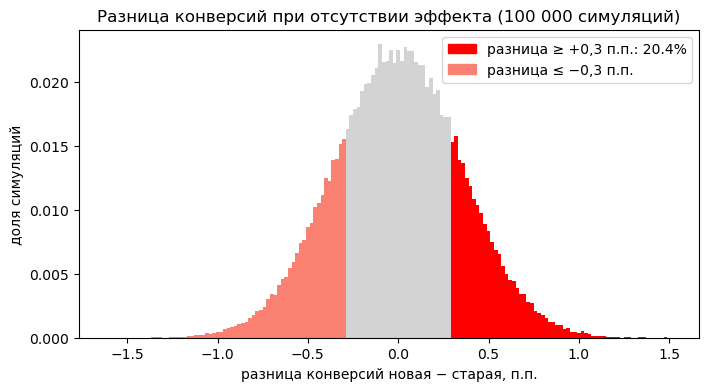

общая конверсия p0 = 0.0325
разница ≥ +0,3 п.п.: 0.204
|разница| ≥ 0,3 п.п.: 0.413
проверка по нормальному приближению: z = 0.85, P(Z ≥ z) = 0.199


In [18]:
n, n_sim = 5000, 100_000
p0 = (155 + 170) / (2 * n)            # общая конверсия при гипотезе «кнопка ни на что не влияет»
obs = 170 - 155                       # наблюдаемая разница в откликах (0,3 п.п. = 15 откликов)

c_old = np.random.binomial(n, p0, size=n_sim)
c_new = np.random.binomial(n, p0, size=n_sim)
d = c_new - c_old                     # разница считается в откликах, чтобы не сравнивать вещественные числа

p_one = (d >= obs).mean()
p_two = (np.abs(d) >= obs).mean()

vals = np.arange(d.min(), d.max() + 1)
freq = np.bincount(d - d.min()) / n_sim
colors = np.where(vals >= obs, 'red', np.where(vals <= -obs, 'salmon', 'lightgray'))
plt.bar(vals / n * 100, freq, width=100 / n, color=colors)
plt.xlabel('разница конверсий новая − старая, п.п.'); plt.ylabel('доля симуляций')
plt.title('Разница конверсий при отсутствии эффекта (100 000 симуляций)')
plt.legend(handles=[Patch(color='red', label=f'разница ≥ +0,3 п.п.: {p_one:.1%}'),
                    Patch(color='salmon', label='разница ≤ −0,3 п.п.')])
plt.show()

print(f'общая конверсия p0 = {p0:.4f}')
print(f'разница ≥ +0,3 п.п.: {p_one:.3f}')
print(f'|разница| ≥ 0,3 п.п.: {p_two:.3f}')
z = obs / n / np.sqrt(2 * p0 * (1 - p0) / n)
print(f'проверка по нормальному приближению: z = {z:.2f}, P(Z ≥ z) = {1 - stats.norm.cdf(z):.3f}')

Даже при полном отсутствии эффекта разница в 0,3 п.п. и больше в пользу новой кнопки возникает примерно в 20% симуляций (в 41% случаев, если считать отклонение в любую сторону). Нормальное приближение дает то же ≈ 0,20 и согласуется с 3.1.

**Ответ:** Это шум. Наблюдаемая разница не редкость при одинаковой конверсии, поэтому эффект новой кнопки по этим данным не подтвержден.

### Задание 3.3. Выбросы во времени сессий

3σ: среднее 10.0, σ 14.83, границы [-34.5; 54.5], выбросы: []
перцентили: p25 4.25, p75 6.75, границы [0.5; 10.5], выбросы: [52]
без значения 52: среднее 5.3, σ 1.58
z-оценка для 52: 2.83; максимально возможная при n = 10: 2.85


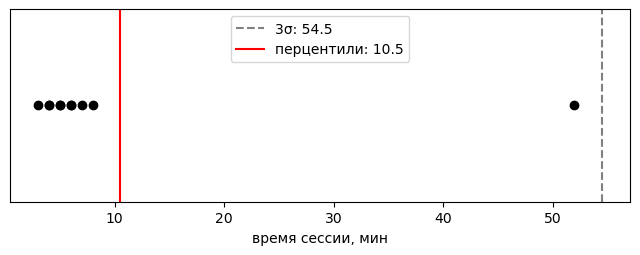

In [19]:
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

m, s = x.mean(), x.std(ddof=1)
low_3s, up_3s = m - 3*s, m + 3*s
out_3s = x[(x < low_3s) | (x > up_3s)]

p25, p75 = np.percentile(x, [25, 75])
low_p, up_p = p25 - 1.5*(p75 - p25), p75 + 1.5*(p75 - p25)
out_p = x[(x < low_p) | (x > up_p)]

print(f'3σ: среднее {m:.1f}, σ {s:.2f}, границы [{low_3s:.1f}; {up_3s:.1f}], выбросы: {out_3s}')
print(f'перцентили: p25 {p25}, p75 {p75}, границы [{low_p}; {up_p}], выбросы: {out_p}')
print(f'без значения 52: среднее {x[:-1].mean():.1f}, σ {x[:-1].std(ddof=1):.2f}')
print(f'z-оценка для 52: {(52 - m)/s:.2f}; максимально возможная при n = 10: {(len(x)-1)/np.sqrt(len(x)):.2f}')

plt.figure(figsize=(8, 2.5))
plt.scatter(x, np.zeros(len(x)), color='black', zorder=3)
plt.axvline(up_3s, color='gray', linestyle='--', label=f'3σ: {up_3s:.1f}')
plt.axvline(up_p, color='red', label=f'перцентили: {up_p:.1f}')
plt.yticks([]); plt.xlabel('время сессии, мин'); plt.legend(loc='upper center')
plt.show()

**Правило трех сигм ничего не нашло, перцентили нашли значение 52 мин.**

- Выброс сам раздувает оценки: среднее 10,0 вместо 5,3 без него, σ = 14,8 вместо 1,6. Граница $\mu+3\sigma=54{,}5$ уезжает дальше самого выброса (52).
- Для выборки из 10 значений правило трех сигм не особо применимо: z-оценка не бывает больше $(n-1)/\sqrt{n}\approx 2{,}85$.
- Перцентили зависят только от порядка значений, а не от их величины: граница $Q_3+1{,}5\cdot IQR=10{,}5$ мин, и 52 явно выше.

Лучше всего сработали перцентили. На данных с длинным хвостом лучше опираться на перцентили, а не на 3 сигм.
Найденный выброс может быть ошибкой логирования или реальной очень долгой сессией.